In [1]:
######### Importing stuff we need #########
import sys
sys.path.append('..')
from consts import *
from functions import *

from physics_functions import *

######### python stuff #########
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.misc as misc
import scipy.special as sp

<!-- ![argon phase diagram](pics/eng_toolbox_phaseDiagram.png) -->

<img src="pics/eng_toolbox_phaseDiagram.png" alt="phase diagram" width="700"/>

# <u> NIST</u> #

<img src="pics/nist_VP.png" alt="vapour pressure" width = 800>

https://webbook.nist.gov/cgi/cbook.cgi?ID=C7440371&Mask=4


In [2]:
#### Parameters ####
# M_argon = 39.948

In [3]:
# things to plot #
temps = np.arange(80, 135, 1)

waves = np.arange(110, 300, 1)

# fig, ax = plt.subplots()

# ax.plot(temps, pVapor_T(temps))
# print(ax.get_ybound())


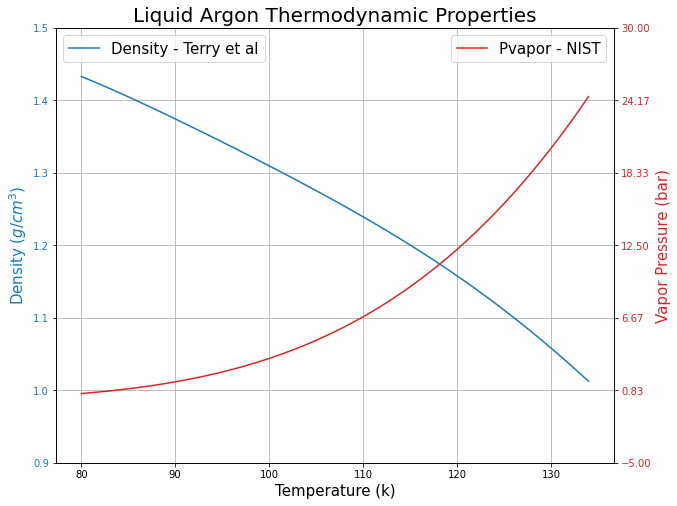

In [4]:
fig, ax1 = plt.subplots(figsize = (10, 8))
ax1.set_title("Liquid Argon Thermodynamic Properties", size = 20)

color = 'tab:blue'

ax1.set_xlabel("Temperature (k)", size = 15)
ax1.set_ylabel("Density ($g/cm^3$)", color = color, size = 15)
ax1.plot(temps, arDensity_Terry(temps), label = "Density - Terry et al", color = color)
ax1.tick_params(axis='y', labelcolor=color)

ogbound1 = ax1.get_ybound()
ax1.set_yticks(np.linspace( ax1.get_yticks()[0], ax1.get_yticks()[-1], len(ax1.get_yticks())))


### second plot ###
ax2 = ax1.twinx()

color='tab:red'
ax2.set_ylabel("Vapor Pressure (bar)", color = color, size = 15)
ax2.tick_params(axis='y', labelcolor=color)

ax2.plot(temps, pVapor_T(temps), color = color, label = "Pvapor - NIST")
ogbound2 = ax2.get_ybound()

ax2.set_yticks( np.linspace(ax2.get_yticks()[0], ax2.get_yticks()[-1], len(ax1.get_yticks())) )

ax1.legend(loc = "upper left", fontsize = 15)
ax2.legend(loc = "upper right", fontsize = 15)
ax1.grid(axis='both', which='major')
plt.show()

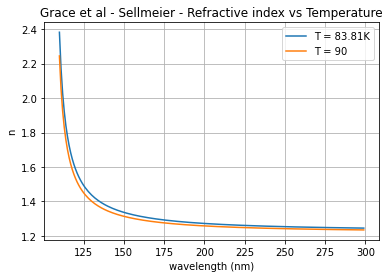

1.4179382792441444


In [26]:

plt.plot(waves, getSellmeierN_T83(waves), label = "T = 83.81K")
plt.plot(waves, getSellmeierN_T90(waves), label = "T = 90")

plt.title("Grace et al - Sellmeier - Refractive index vs Temperature")
plt.ylabel("n")
plt.xlabel("wavelength (nm)")
plt.legend()

plt.grid()
plt.savefig("nvsT.png")
plt.show()

print(getSellmeierN_T90(128))



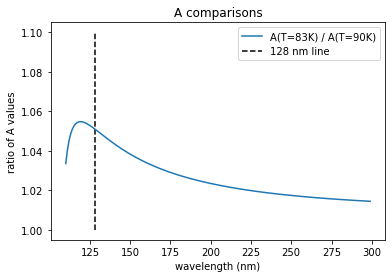

In [24]:
a83 = getAlambda(waves, 83.81, getSellmeierN_T83, arDensity_Terry)

a90 = getAlambda(waves, 90, getSellmeierN_T90, arDensity_Terry)

plt.vlines(x = 128, ymin = 1., ymax = 1.1, linestyle = '--', color = 'k', label = "128 nm line")
plt.plot(waves, a83/a90, label = "A(T=83K) / A(T=90K)")

plt.title("A comparisons")
plt.xlabel("wavelength (nm)")
plt.ylabel("ratio of A values")
plt.legend()
plt.show()

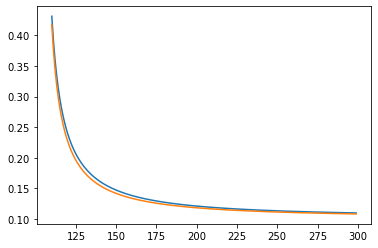

In [27]:
plt.plot(waves, a83)
plt.plot(waves, a90)
# plt.plot(waves, getMeanAlambda(waves, arDensity_Terry))

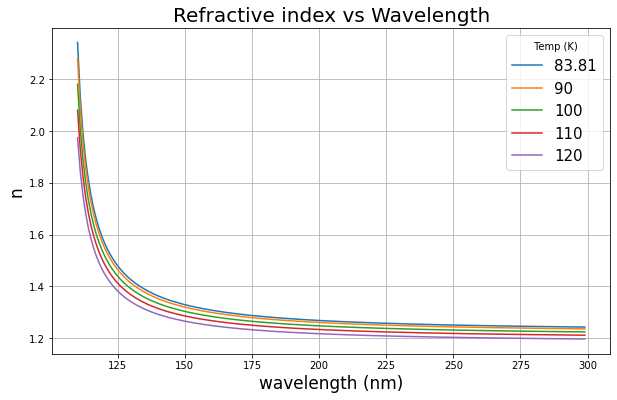

In [28]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))

ax.plot(waves, getMeanN_lamT(waves, 83.81, arDensity_Terry), label = "83.81")

ax.plot(waves, getMeanN_lamT(waves, 90, arDensity_Terry), label = "90")

ax.plot(waves, getMeanN_lamT(waves, 100, arDensity_Terry), label = "100")

ax.plot(waves, getMeanN_lamT(waves, 110, arDensity_Terry), label = "110")

ax.plot(waves, getMeanN_lamT(waves, 120, arDensity_Terry), label = "120")

ax.set_title("Refractive index vs Wavelength", size = 20)
ax.set_ylabel("n", size = 17)
ax.set_xlabel("wavelength (nm)", size = 17)
ax.legend(title = " Temp (K)", fontsize = 15)

ax.grid()
plt.show()

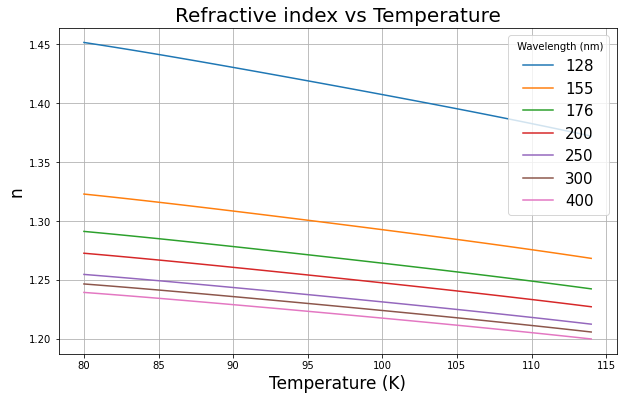

In [29]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))

# temps = temps[0:-20]
ax.plot(temps, getMeanN_lamT(128, temps, arDensity_Terry), label = "128")

ax.plot(temps, getMeanN_lamT(155, temps, arDensity_Terry), label = "155")

ax.plot(temps, getMeanN_lamT(176, temps, arDensity_Terry), label = "176")

ax.plot(temps, getMeanN_lamT(200, temps, arDensity_Terry), label = "200")

ax.plot(temps, getMeanN_lamT(250, temps, arDensity_Terry), label = "250")

ax.plot(temps, getMeanN_lamT(300, temps, arDensity_Terry), label = "300")

ax.plot(temps, getMeanN_lamT(400, temps, arDensity_Terry), label = "400")

ax.set_title("Refractive index vs Temperature", size = 20)
ax.set_ylabel("n", size = 17)
ax.set_xlabel("Temperature (K)", size = 17)

ax.legend(title = " Wavelength (nm)", fontsize = 15)

ax.grid()
plt.show()